# Granite Embedding 748M Vision R2: examples

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibm-granite/granite-embedding-models/blob/main/code/granite_embedding_748m_vision_r2_examples.ipynb)

Can you find a Spanish invoice with a question in Japanese? What if all you have is a screenshot of a chart? Search a small archive of reports, policies, invoices, product sheets and illustrations to see what [Granite Embedding 748M Vision R2](https://huggingface.co/ibm-granite/granite-embedding-748m-vision-r2) can do with page images directly.

- **Sections 1–3** show how a 768-dimensional vector shortlists pages and how 128-dimensional token vectors rerank them with MaxSim. One forward pass produces both.
- **Sections 4–7** search across languages and scans, trace query matches on the page, search by screenshot, and route documents by type.
- **Sections 8–9** put text notes and page images in one index and explore how much space the index needs.
- **Sections 10–12** retrieve chart and table regions, group an unlabeled archive, and compare a rescan with a nearly identical invoice.

**Runtime:** a GPU is recommended (in Colab: *Runtime → Change runtime type → T4 GPU* or better). Ampere and newer GPUs (L4, A100, H100) run the model in bf16; older ones such as the T4 run it in float32. A CPU works, but slowly.

In [ ]:
# Install into the active notebook kernel with uv. MultiVectorEncoder requires Sentence Transformers 6+.
%pip install -q uv
import sys

# --python targets this kernel's interpreter, so the packages land in the right environment (Colab or a local venv).
!uv pip install -q --python {sys.executable} -U "sentence-transformers>=6" pillow matplotlib scipy

## Setup

Load the model and the example pages: four one-page business documents in four languages (an English quarterly report, a French travel policy, a Spanish invoice and a Japanese product sheet), an encyclopedia drawing of an elephant, and a bedroom photograph. Simulated scans of the four documents are used in section 4.

In [17]:
import os
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub import snapshot_download
from PIL import Image
from sentence_transformers import MultiVectorEncoder

# Override the model ID with a local checkpoint path when running offline.
MODEL_ID = os.environ.get("GRANITE_VISION_MODEL", "ibm-granite/granite-embedding-748m-vision-r2")

device = "cuda" if torch.cuda.is_available() else "cpu"
# bf16 needs an Ampere or newer GPU; older GPUs (such as the T4) and CPUs use float32.
dtype = torch.bfloat16 if device == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else torch.float32

# Load the model's custom encoder and both embedding heads.
model = MultiVectorEncoder(MODEL_ID, trust_remote_code=True, device=device, model_kwargs={"dtype": dtype})
# Keep the image processor and tokenizer for mapping token matches back to the page.
processor = model[0].processor
tokenizer = processor.tokenizer
print(f"{MODEL_ID} on {device} ({dtype}), {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

Loading weights: 100%|██████████| 608/608 [00:00<00:00, 11198.81it/s]


ibm-granite/granite-embedding-748m-vision-r2 on cuda (torch.bfloat16), 748.3M parameters


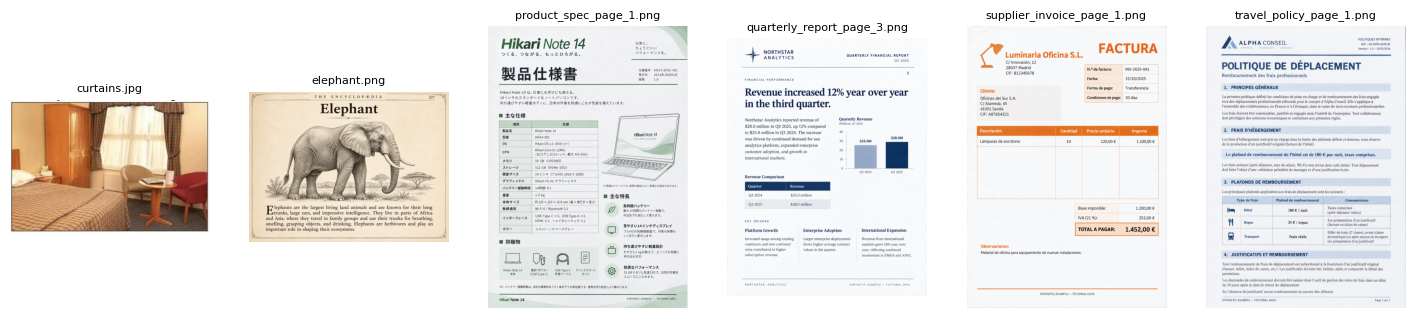

In [18]:
# The example pages are hosted in the model's Hugging Face Space; a local images/ folder is used instead if there is one.
IMAGES_REPO = "ibm-granite/granite-embedding-748m-vision-r2"
if Path("images").is_dir():
    root = Path(".")
else:
    # On a fresh runtime, fetch only the example images (as folders or as artifacts/images.zip).
    root = Path(snapshot_download(IMAGES_REPO, repo_type="space",
                                  allow_patterns=["images/*", "degraded-images/*", "artifacts/images.zip"]))
    archive = root / "artifacts" / "images.zip"
    if not (root / "images").is_dir() and archive.is_file():
        # The zip holds images/ and degraded-images/; unpack it next to the notebook.
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(".")
        root = Path(".")


def load_pages(folder):
    # Use filenames as stable identifiers for matching each scan to its clean page.
    return {p.name: Image.open(p).convert("RGB")
            for p in sorted((root / folder).iterdir()) if p.suffix.lower() in {".png", ".jpg", ".jpeg"}}


pages = load_pages("images")
# Keep this order for the page vectors and the columns in each score matrix.
page_names = list(pages)

fig, axes = plt.subplots(1, len(pages), figsize=(3 * len(pages), 4))
for ax, (name, page) in zip(axes, pages.items()):
    ax.imshow(page)
    ax.set_title(name, fontsize=8)
    ax.axis("off")
plt.show()

## 1. Multi-vector search (MaxSim)

`encode_query` and `encode_document` with `output_value=None` return everything from one forward pass: the token ids, the per-token multi-vectors and the single vector. The multi-vectors are padded to the length of the longest input in the batch, so keep only the real tokens (`attention_mask`); padding vectors would inflate MaxSim scores.

MaxSim scores a query against a page by taking, for each query token, its best dot product with any page token, and adding those maxima up.

In [19]:
def encode(items, kind):
    """Encode queries (kind="query") or pages/passages (kind="document"); returns multi-vectors, single vectors, token ids."""
    encode_fn = model.encode_query if kind == "query" else model.encode_document
    with torch.inference_mode():
        # Request both embedding heads and the token metadata in a single forward pass.
        outputs = encode_fn(items, output_value=None)
    # Drop batch padding from the token vectors and IDs using the same mask.
    keep = [o["attention_mask"].bool() for o in outputs]
    multi = [o["token_embeddings"][k].float().cpu() for o, k in zip(outputs, keep)]
    # One vector per input stacks into a matrix for cosine search.
    single = torch.stack([o["sentence_embedding"] for o in outputs]).float().cpu()
    ids = [o["input_ids"][k].cpu() for o, k in zip(outputs, keep)]
    return multi, single, ids


def maxsim(query_multi, doc_multi):
    """MaxSim scores, shape (queries, documents)."""
    # For each query token, keep its highest dot product with any document token, then sum.
    return torch.tensor([[(q @ d.T).max(dim=1).values.sum().item() for d in doc_multi] for q in query_multi])


def show_ranking(title, queries, scores, names, expected=None, top=3, fmt=".2f"):
    print(f"=== {title}")
    for i, query in enumerate(queries):
        print(f"{query}")
        # Each score row belongs to one query, and column indices point to names.
        for rank, j in enumerate(scores[i].argsort(descending=True)[:top].tolist(), start=1):
            mark = "✓" if expected and names[j] == expected[i] else " "
            print(f"  {mark} {rank}. {names[j]:<30} {scores[i, j]:{fmt}}")
    print()


# Encode the archive once and reuse its embeddings across examples.
page_multi, page_single, page_ids = encode(list(pages.values()), "document")
print("Vectors per page:", {name: len(v) for name, v in zip(page_names, page_multi)})
print("Multi-vector width:", page_multi[0].shape[1], "| single vector width:", page_single.shape[1])

Vectors per page: {'curtains.jpg': 229, 'elephant.png': 683, 'product_spec_page_1.png': 589, 'quarterly_report_page_3.png': 547, 'supplier_invoice_page_1.png': 589, 'travel_policy_page_1.png': 589}
Multi-vector width: 128 | single vector width: 768


In [20]:
# Each query in the language of its page, plus two questions about the pictures.
queries = {
    "How much did revenue grow in the third quarter?": "quarterly_report_page_3.png",
    "Quel est le plafond pour l'hôtel ?": "travel_policy_page_1.png",
    "¿Cuál es el importe total de la factura?": "supplier_invoice_page_1.png",
    "この製品のバッテリー駆動時間は何時間ですか？": "product_spec_page_1.png",
    "What do elephants use their trunks and tusks for?": "elephant.png",
    "What pattern are the curtains in the bedroom?": "curtains.jpg",
}
# Keep the expected page names in query order so the ranking can mark correct hits.
query_texts, expected = list(queries), list(queries.values())
query_multi, query_single, query_ids = encode(query_texts, "query")

# Score every query against every indexed page.
mv_scores = maxsim(query_multi, page_multi)
# model.similarity computes the same MaxSim scores.
assert torch.allclose(mv_scores, torch.as_tensor(model.similarity(query_multi, page_multi)).float(), atol=1e-2)
show_ranking("Multi-vector (MaxSim)", query_texts, mv_scores, page_names, expected)

=== Multi-vector (MaxSim)
How much did revenue grow in the third quarter?
  ✓ 1. quarterly_report_page_3.png    9.64
    2. supplier_invoice_page_1.png    7.26
    3. travel_policy_page_1.png       7.04
Quel est le plafond pour l'hôtel ?
  ✓ 1. travel_policy_page_1.png       7.93
    2. curtains.jpg                   7.24
    3. supplier_invoice_page_1.png    6.42
¿Cuál es el importe total de la factura?
  ✓ 1. supplier_invoice_page_1.png    9.06
    2. travel_policy_page_1.png       7.82
    3. quarterly_report_page_3.png    7.26
この製品のバッテリー駆動時間は何時間ですか？
  ✓ 1. product_spec_page_1.png        8.55
    2. curtains.jpg                   6.47
    3. supplier_invoice_page_1.png    6.39
What do elephants use their trunks and tusks for?
  ✓ 1. elephant.png                   10.19
    2. curtains.jpg                   7.69
    3. product_spec_page_1.png        7.55
What pattern are the curtains in the bedroom?
  ✓ 1. curtains.jpg                   8.25
    2. travel_policy_page_1.png       6.26

## 2. Single-vector search, and Matryoshka truncation

The single vector is the L2-normalized `[CLS]` embedding, scored with cosine similarity, so it works in any vector database. It was trained with Matryoshka representation learning: its first 128, 256, 384 or 512 dimensions, re-normalized, are a smaller embedding of the same input.

In [21]:
# A dot product between normalized vectors gives cosine similarity.
sv_scores = query_single @ page_single.T
show_ranking("Single vector (cosine), 768-d", query_texts, sv_scores, page_names, expected, fmt=".3f")


def truncate(vectors, dims):
    # Keep the first dims coordinates and restore unit length before scoring.
    return torch.nn.functional.normalize(vectors[:, :dims], dim=-1)


print("Correct page ranked first, by single-vector size:")
for dims in (768, 512, 384, 256, 128):
    scores = truncate(query_single, dims) @ truncate(page_single, dims).T
    # Count queries whose highest-scoring page is the expected one.
    correct = sum(page_names[j] == e for j, e in zip(scores.argmax(dim=1).tolist(), expected))
    print(f"  {dims:>3}-d ({dims * 2:>4} bytes in fp16): {correct}/{len(expected)}")

=== Single vector (cosine), 768-d
How much did revenue grow in the third quarter?
  ✓ 1. quarterly_report_page_3.png    0.865
    2. supplier_invoice_page_1.png    0.670
    3. travel_policy_page_1.png       0.633
Quel est le plafond pour l'hôtel ?
    1. curtains.jpg                   0.755
  ✓ 2. travel_policy_page_1.png       0.735
    3. supplier_invoice_page_1.png    0.681
¿Cuál es el importe total de la factura?
  ✓ 1. supplier_invoice_page_1.png    0.828
    2. travel_policy_page_1.png       0.730
    3. quarterly_report_page_3.png    0.688
この製品のバッテリー駆動時間は何時間ですか？
  ✓ 1. product_spec_page_1.png        0.750
    2. supplier_invoice_page_1.png    0.622
    3. curtains.jpg                   0.613
What do elephants use their trunks and tusks for?
  ✓ 1. elephant.png                   0.812
    2. curtains.jpg                   0.637
    3. product_spec_page_1.png        0.616
What pattern are the curtains in the bedroom?
  ✓ 1. curtains.jpg                   0.851
    2. product_spec

## 3. Hybrid search: single-vector shortlist, multi-vector rerank

Use cosine similarity to shortlist pages, then compute MaxSim only for those candidates. In the saved run, the French hotel question puts the bedroom photo first by cosine similarity. MaxSim moves the travel policy to first place. With two candidates per query, this example scores 12 of the 36 possible query–page pairs with MaxSim.

In [22]:
SHORTLIST = 2

print(f"=== Single-vector top {SHORTLIST}, reranked with MaxSim")
for i, query in enumerate(query_texts):
    # Use cosine similarity to pick candidates before scoring their token vectors.
    shortlist = sv_scores[i].argsort(descending=True)[:SHORTLIST].tolist()
    scores = maxsim([query_multi[i]], [page_multi[j] for j in shortlist])[0]
    print(query)
    for position in scores.argsort(descending=True).tolist():
        # MaxSim scores follow shortlist order. Map the position back to the full index.
        j = shortlist[position]
        mark = "✓" if page_names[j] == expected[i] else " "
        print(f"  {mark} {page_names[j]:<30} cosine {sv_scores[i, j]:.3f}   MaxSim {scores[position]:.2f}")

=== Single-vector top 2, reranked with MaxSim
How much did revenue grow in the third quarter?
  ✓ quarterly_report_page_3.png    cosine 0.865   MaxSim 9.64
    supplier_invoice_page_1.png    cosine 0.670   MaxSim 7.26
Quel est le plafond pour l'hôtel ?
  ✓ travel_policy_page_1.png       cosine 0.735   MaxSim 7.93
    curtains.jpg                   cosine 0.755   MaxSim 7.24
¿Cuál es el importe total de la factura?
  ✓ supplier_invoice_page_1.png    cosine 0.828   MaxSim 9.06
    travel_policy_page_1.png       cosine 0.730   MaxSim 7.82
この製品のバッテリー駆動時間は何時間ですか？
  ✓ product_spec_page_1.png        cosine 0.750   MaxSim 8.55
    supplier_invoice_page_1.png    cosine 0.622   MaxSim 6.39
What do elephants use their trunks and tusks for?
  ✓ elephant.png                   cosine 0.812   MaxSim 10.19
    curtains.jpg                   cosine 0.637   MaxSim 7.69
What pattern are the curtains in the bedroom?
  ✓ curtains.jpg                   cosine 0.851   MaxSim 8.25
    product_spec_page_1.png 

## 4. Queries in other languages, and simulated scans

The text encoder is multilingual, so a query need not be in the language of the page. Below, each document is asked about in a different language. Then the same-language queries are run against simulated scans of the pages (light noise, softness and skew).

In [23]:
cross_language = {
    "Um wie viel Prozent ist der Umsatz im dritten Quartal gestiegen?": "quarterly_report_page_3.png",  # German → English page
    "What is the maximum hotel reimbursement per night?": "travel_policy_page_1.png",                  # English → French page
    "この請求書の支払総額はいくらですか？": "supplier_invoice_page_1.png",                                # Japanese → Spanish page
    "Quelle est l'autonomie de la batterie de cet ordinateur portable ?": "product_spec_page_1.png",   # French → Japanese page
}
# Change the query language while reusing the original page index.
cross_multi, _, _ = encode(list(cross_language), "query")
show_ranking("Cross-language, multi-vector", list(cross_language), maxsim(cross_multi, page_multi),
             page_names, list(cross_language.values()))

scans = load_pages("degraded-images")
scan_names = list(scans)
scan_multi, scan_single, _ = encode(list(scans.values()), "document")
# Reuse the same-language query embeddings for the pages with scan variants.
document_queries = [q for q, page in queries.items() if page in scans]
document_multi = [query_multi[query_texts.index(q)] for q in document_queries]
# Score clean pages in scan order so each score can be compared with its scan counterpart.
original = maxsim(document_multi, [page_multi[page_names.index(n)] for n in scan_names])
scanned = maxsim(document_multi, scan_multi)
show_ranking("Same-language queries against the simulated scans", document_queries, scanned,
             scan_names, [queries[q] for q in document_queries])
print(f"Largest change in any MaxSim score from original to scan: {(scanned - original).abs().max():.3f}")

=== Cross-language, multi-vector
Um wie viel Prozent ist der Umsatz im dritten Quartal gestiegen?
  ✓ 1. quarterly_report_page_3.png    12.14
    2. supplier_invoice_page_1.png    9.45
    3. product_spec_page_1.png        8.95
What is the maximum hotel reimbursement per night?
  ✓ 1. travel_policy_page_1.png       8.00
    2. curtains.jpg                   6.73
    3. product_spec_page_1.png        6.53
この請求書の支払総額はいくらですか？
  ✓ 1. supplier_invoice_page_1.png    8.90
    2. travel_policy_page_1.png       7.40
    3. product_spec_page_1.png        6.93
Quelle est l'autonomie de la batterie de cet ordinateur portable ?
  ✓ 1. product_spec_page_1.png        11.65
    2. curtains.jpg                   9.72
    3. supplier_invoice_page_1.png    9.39

=== Same-language queries against the simulated scans
How much did revenue grow in the third quarter?
  ✓ 1. quarterly_report_page_3.png    9.63
    2. supplier_invoice_page_1.png    7.31
    3. travel_policy_page_1.png       7.02
Quel est le pla

## 5. Where does the query look? The elephant example

Every visual token of a page comes from a known cell of the page: the connector emits rows of cells in reading order, with a newline token ending each row. So for each query token, the page token that wins its MaxSim maximum can be drawn on the page.

The left panel shows where each query token found its best match, numbered in query order. The other panels show how similar one query token is to every cell of the page. Read them as a view into the scoring, not as text detection: page tokens pass through the text encoder and carry context from around the page, so a match can land next to the words or drawing it refers to.

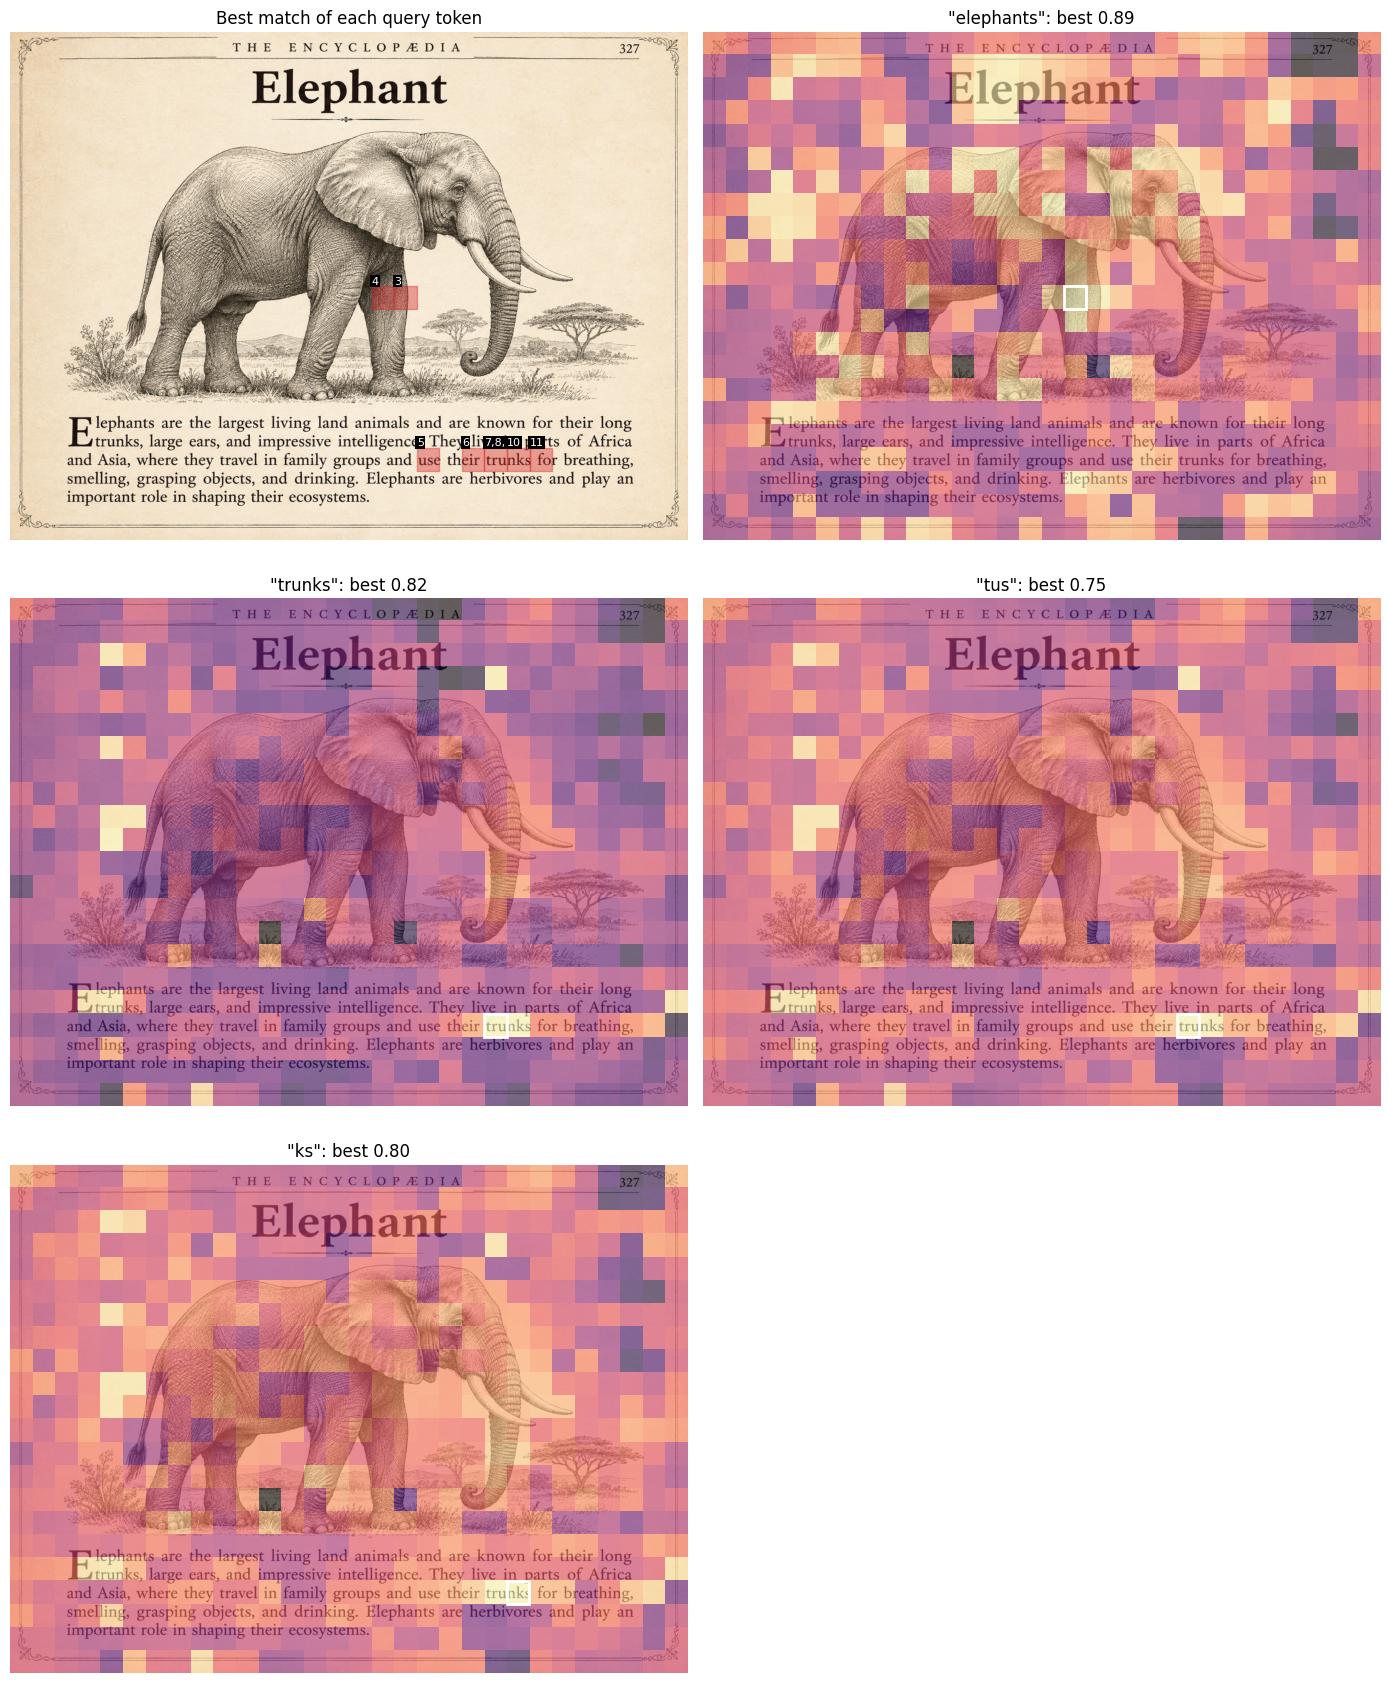

Query tokens: 1 <bos>, 2 What, 3 do, 4 elephants, 5 use, 6 their, 7 trunks, 8 and, 9 tus, 10 ks, 11 for, 12 ?
Best match on a token with no place on the page (start or row-end token): ['<bos>', 'What', '?']


In [24]:
from matplotlib.patches import Rectangle

image_processor = processor.image_processor


def page_grid(page, token_ids):
    """Grid size of a page, and the (row, col) cell of each page token (None for tokens with no place on the page)."""
    # Read the patch grid from the processor and apply the model's spatial downsampling.
    patch_h, patch_w = (int(s) for s in image_processor([page])["spatial_shapes"][0])
    query_side, window_side = (int(s) for s in image_processor.downsample_rate.split("/"))
    rows, cols = patch_h * query_side // window_side, patch_w * query_side // window_side
    # Include the optional row-end token when converting a flat offset to a grid position.
    row_length = cols + int(processor.use_image_newline)
    positions = (token_ids == processor.image_token_id).nonzero().squeeze(-1).tolist()
    # Leave special tokens without a drawable grid position.
    cells = [None] * len(token_ids)
    for offset, position in enumerate(positions):
        row, col = divmod(offset, row_length)
        if col < cols:  # the last token of each row is the newline
            cells[position] = (row, col)
    return rows, cols, cells


def show_query_on_page(query, page_name, show_tokens):
    (q,), _, (q_ids,) = encode([query], "query")
    d, ids, page = page_multi[page_names.index(page_name)], page_ids[page_names.index(page_name)], pages[page_name]
    rows, cols, cells = page_grid(page, ids)
    similarity = q @ d.T  # query tokens × page tokens
    # Find the winning page token for each query token, including special tokens.
    best = similarity.argmax(dim=1).tolist()
    labels = [t.replace("▁", "") for t in tokenizer.convert_ids_to_tokens(q_ids.tolist())]
    width, height = page.size
    # Map the grid back to the displayed image in pixel coordinates.
    cell_w, cell_h = width / cols, height / rows

    panels = 1 + len(show_tokens)
    ncols = min(panels, 2 if width > height else 3)
    nrows = -(-panels // ncols)
    panel_w = 7 if width > height else 5
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, (panel_w * height / width + 0.5) * nrows), squeeze=False)
    axes = axes.ravel()
    for ax in axes[panels:]:
        ax.remove()
    axes = axes[:panels]
    axes[0].imshow(page)
    axes[0].set_title("Best match of each query token")
    # Group query-token labels if multiple tokens pick the same page cell.
    numbers = {}
    for i, token in enumerate(best):
        if cells[token] is not None:
            numbers.setdefault(cells[token], []).append(str(i + 1))
    for (row, col), nums in numbers.items():
        axes[0].add_patch(Rectangle((col * cell_w, row * cell_h), cell_w, cell_h, color="tab:red", alpha=0.4))
        axes[0].text(col * cell_w, row * cell_h, ",".join(nums), fontsize=8, color="white", va="bottom",
                     bbox=dict(facecolor="black", pad=1, linewidth=0))

    for ax, label in zip(axes[1:], show_tokens):
        t = labels.index(label)
        # Fill the heatmap with this token's scores at the drawable page cells.
        heat = np.full((rows, cols), np.nan)
        for token, cell in enumerate(cells):
            if cell is not None:
                heat[cell] = similarity[t, token].item()
        ax.imshow(page)
        ax.imshow(heat, extent=(0, width, height, 0), cmap="magma", alpha=0.6)
        if cells[best[t]] is not None:
            row, col = cells[best[t]]
            ax.add_patch(Rectangle((col * cell_w, row * cell_h), cell_w, cell_h, fill=False, edgecolor="white", linewidth=2))
        # matplotlib's default font has no CJK glyphs, so non-ASCII tokens are named by their number.
        name = f'"{label}"' if label.isascii() else f"token {t + 1}"
        ax.set_title(f"{name}: best {similarity[t].max():.2f}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    print("Query tokens:", ", ".join(f"{i + 1} {label}" for i, label in enumerate(labels)))
    # Report the winning tokens that could not be drawn on the page.
    no_place = [labels[i] for i, token in enumerate(best) if cells[token] is None]
    print("Best match on a token with no place on the page (start or row-end token):", no_place or "none")


show_query_on_page("What do elephants use their trunks and tusks for?", "elephant.png", ["elephants", "trunks", "tus", "ks"])

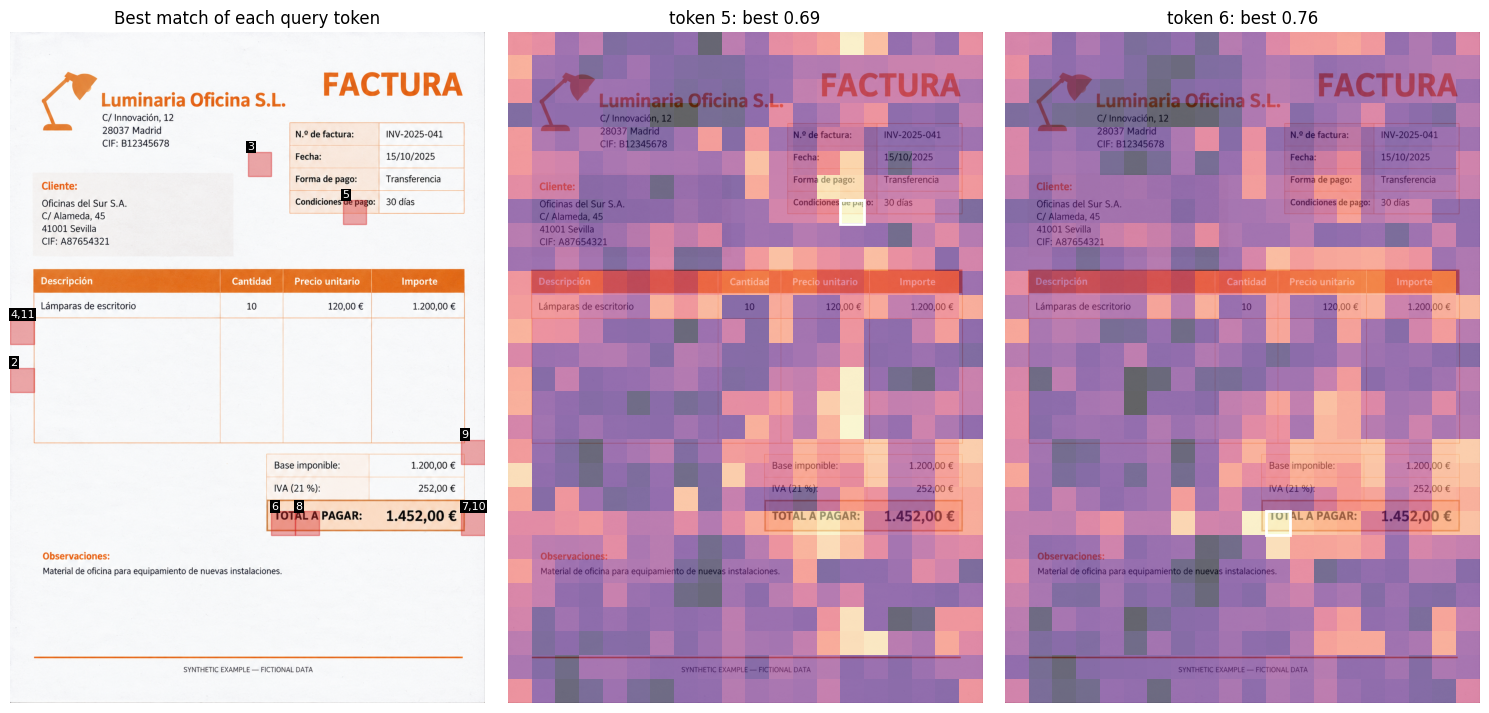

Query tokens: 1 <bos>, 2 この, 3 請求, 4 書の, 5 支払, 6 総, 7 額, 8 は, 9 いく, 10 ら, 11 ですか, 12 ？
Best match on a token with no place on the page (start or row-end token): ['<bos>', '？']


In [25]:
# The same view for a cross-language query: a Japanese question about the Spanish invoice.
# The last argument selects the Japanese tokens shown in the individual heatmaps.
show_query_on_page("この請求書の支払総額はいくらですか？", "supplier_invoice_page_1.png", ["支払", "総"])

## 6. Find the source page from a screenshot

Someone sends you a cropped chart or table without the surrounding page. Where did it come from? Crop two simulated scans and search the original archive using the crops as probes. Encode both sides with `encode_document` and compare their single vectors by cosine similarity. This is an image-to-image experiment with a model trained for text-to-page retrieval. The panels show the top match and its cosine similarity, and the printed ranks tell you where each known original landed.

Revenue chart · original ranked 1 of 6
Reimbursement table · original ranked 1 of 6


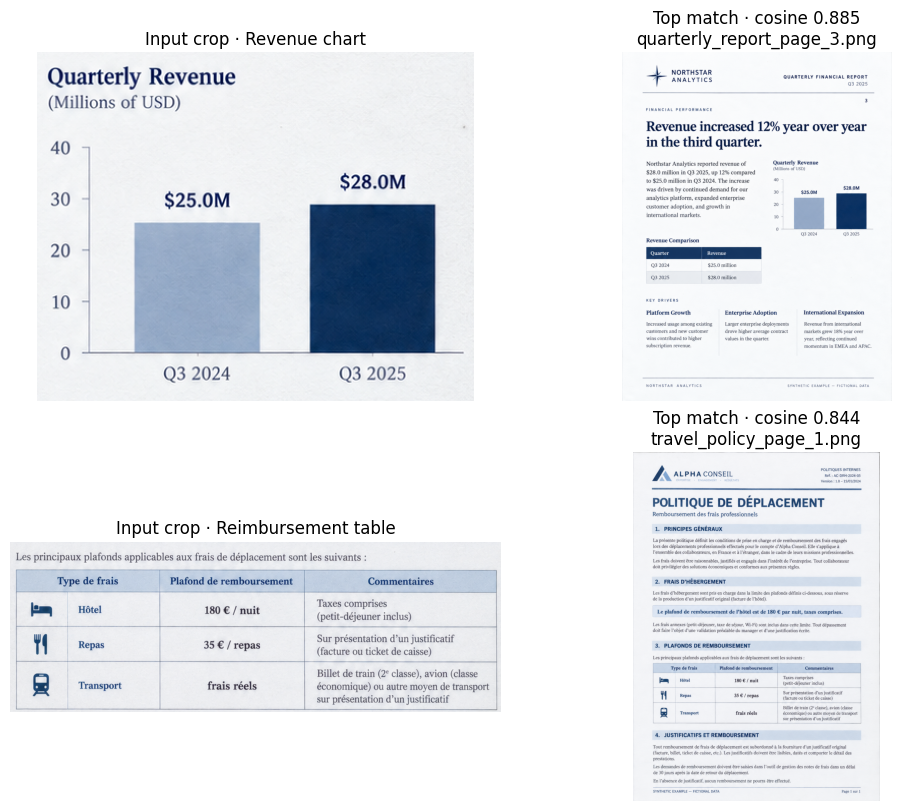

In [26]:
def pixel_box(image, box):
    """Convert a relative (left, top, right, bottom) box to pixel coordinates."""
    width, height = image.size
    left, top, right, bottom = box
    return (round(left * width), round(top * height), round(right * width), round(bottom * height))


# Crop coordinates are fractions of the scan.
snippets = [
    ("Revenue chart", "quarterly_report_page_3.png", (0.55, 0.30, 0.94, 0.54)),
    ("Reimbursement table", "travel_policy_page_1.png", (0.07, 0.57, 0.93, 0.78)),
]
crops = [scans[name].crop(pixel_box(scans[name], box)) for _, name, box in snippets]

# Encode the input images on the document side and compare them with the full-page vectors.
_, crop_single, _ = encode(crops, "document")
crop_scores = crop_single @ page_single.T

fig, axes = plt.subplots(len(snippets), 2, figsize=(10, 4 * len(snippets)), layout="constrained")
for (title, source_name, _), crop, scores, (query_ax, match_ax) in zip(snippets, crops, crop_scores, axes):
    ranking = scores.argsort(descending=True).tolist()
    best = ranking[0]
    # Find the known source's one-based rank even when another page scores higher.
    source_rank = ranking.index(page_names.index(source_name)) + 1
    print(f"{title} · original ranked {source_rank} of {len(page_names)}")
    query_ax.imshow(crop)
    query_ax.set_title(f"Input crop · {title}")
    match_ax.imshow(pages[page_names[best]])
    match_ax.set_title(f"Top match · cosine {scores[best]:.3f}\n{page_names[best]}")
    for ax in (query_ax, match_ax):
        ax.axis("off")
plt.show()

## 7. Route incoming pages by type

Say each incoming scan needs to go to the right queue. Describe the queues in English, embed those descriptions as queries, and score each scan against them. The highest cosine similarity assigns the queue. The table lets you compare the predicted type with the known type and inspect the runner-up. Try changing a description and see whether the routes change.

In [27]:
# Embed the descriptions as queries so each queue has a semantic vector.
queues = {
    "Finance": "A quarterly financial report summarizing revenue, year-over-year growth, and business performance.",
    "Travel": "An employee travel policy explaining reimbursement limits for hotels, meals, and transport.",
    "Accounts payable": "A supplier invoice listing line items, taxes, and the total amount due.",
    "Product": "A laptop specification sheet listing hardware, features, and battery life.",
}
# Use these reference labels to check the predictions.
expected_queues = {
    "quarterly_report_page_3.png": "Finance",
    "travel_policy_page_1.png": "Travel",
    "supplier_invoice_page_1.png": "Accounts payable",
    "product_spec_page_1.png": "Product",
}
_, queue_single, _ = encode(list(queues.values()), "query")
# Rows are scans and columns are queues, with one cosine score per pairing.
queue_scores = scan_single @ queue_single.T
queue_names = list(queues)

for name, scores in zip(scan_names, queue_scores):
    # Show the next-best score so readers can see how close the decision was.
    best, runner_up = scores.topk(2).indices.tolist()
    print(f"{name:<30} {queue_names[best]:<17} {scores[best]:.3f}   "
          f"runner-up {queue_names[runner_up]} ({scores[runner_up]:.3f})   expected {expected_queues[name]}")

product_spec_page_1.png        Product           0.815   runner-up Finance (0.670)   expected Product
quarterly_report_page_3.png    Finance           0.855   runner-up Accounts payable (0.659)   expected Finance
supplier_invoice_page_1.png    Accounts payable  0.761   runner-up Finance (0.707)   expected Accounts payable
travel_policy_page_1.png       Travel            0.802   runner-up Accounts payable (0.703)   expected Travel


## 8. Retrieve text notes and page images together

An archive might contain a scanned report and a plain-text note about the same quarter. Encode the notes with `encode_document` in a separate batch and add them to the page index. A single query can then retrieve both the note and the source page. In a retrieval-augmented generation (RAG) system, pass the top passages and page images to a vision-language model so it can answer from the text, tables, or figures it finds there.

In [28]:
passages = [
    "Revenue grew 12% year over year in the third quarter, from $25.0 million to $28.0 million.",
    "Hotel stays on business trips are reimbursed up to €180 per night, including taxes.",
    "Elephants use their trunks to breathe, smell, drink and grab food, and their tusks to dig and to defend themselves.",
    "The office will be closed on Monday for the public holiday.",
]
# Encode text documents in their own batch, then combine the resulting vectors with the pages.
passage_multi, passage_single, _ = encode(passages, "document")

# Keep display names and both vector collections in the same order.
index_names = page_names + [f"text: {p[:40]}…" for p in passages]
index_multi = page_multi + passage_multi
index_single = torch.cat([page_single, passage_single])

mixed_queries = ["How much did revenue grow in the third quarter?", "What do elephants use their trunks and tusks for?",
                 "Is the office open on Monday?"]
# Score the same mixed collection with both embedding heads.
mixed_multi, mixed_single, _ = encode(mixed_queries, "query")
show_ranking("Mixed index, multi-vector", mixed_queries, maxsim(mixed_multi, index_multi), index_names)
show_ranking("Mixed index, single vector", mixed_queries, mixed_single @ index_single.T, index_names, fmt=".3f")

=== Mixed index, multi-vector
How much did revenue grow in the third quarter?
    1. text: Revenue grew 12% year over year in the t… 10.15
    2. quarterly_report_page_3.png    9.64
    3. text: Hotel stays on business trips are reimbu… 7.30
What do elephants use their trunks and tusks for?
    1. text: Elephants use their trunks to breathe, s… 11.25
    2. elephant.png                   10.21
    3. curtains.jpg                   7.70
Is the office open on Monday?
    1. text: The office will be closed on Monday for … 7.41
    2. supplier_invoice_page_1.png    5.72
    3. text: Hotel stays on business trips are reimbu… 5.41

=== Mixed index, single vector
How much did revenue grow in the third quarter?
    1. text: Revenue grew 12% year over year in the t… 0.916
    2. quarterly_report_page_3.png    0.865
    3. text: The office will be closed on Monday for … 0.679
What do elephants use their trunks and tusks for?
    1. text: Elephants use their trunks to breathe, s… 0.936
    2. ele

## 9. Index size: token pooling and int8

A page is stored as one 128-d vector per token. Two index-time compressions shrink that without retraining:

- **Token pooling.** Cluster a page's vectors hierarchically (Ward) down to a budget and replace each cluster by its re-normalized mean; queries are not pooled. The model was trained with this pooling at budgets of 32 to 300 vectors, so it costs little quality.
- **int8.** Store each vector as 8-bit integers with one scale per vector.

On six pages this is only a sanity check; the model card reports the effect on full benchmarks.

In [29]:
from scipy.cluster.hierarchy import fcluster, linkage


def pool(vectors, budget):
    """Hierarchical token pooling to at most `budget` vectors; the first token ([CLS]) is kept as is."""
    if len(vectors) <= budget:
        return vectors
    # Reserve one slot for the first token and cluster the remaining vectors.
    head, rest = vectors[:1], vectors[1:]
    # Ward on unit vectors: squared Euclidean distance is 2 - 2 cos, so this clusters by cosine distance.
    labels = fcluster(linkage(rest.numpy(), method="ward"), t=budget - 1, criterion="maxclust")
    # Replace each cluster with its mean, normalized back to unit length.
    centroids = torch.stack([rest[torch.from_numpy(labels == k)].mean(dim=0) for k in np.unique(labels)])
    return torch.cat([head, torch.nn.functional.normalize(centroids, dim=-1)])


def int8_roundtrip(vectors):
    # Map each vector's largest magnitude to 127. Return dequantized floats for MaxSim.
    scale = vectors.abs().amax(dim=1, keepdim=True) / 127
    return (vectors / scale).round().clamp(-127, 127) * scale


# Estimate the bytes in the stored vector values, excluding scales and index metadata.
full_bytes = sum(len(v) for v in page_multi) * 128 * 2 / len(page_multi)
print(f"Mean vectors per page: {sum(len(v) for v in page_multi) / len(page_multi):.0f}, "
      f"{full_bytes / 1024:.0f} KiB per page in fp16 (the single vector: 1.5 KiB)\n")
print(f"{'Index':<22}{'KiB/page':>9}{'Top-1 correct':>15}{'Mean score kept':>17}")
for label, transform, bytes_per_value in [
    ("full, fp16", lambda v: v, 2),
    ("int8", int8_roundtrip, 1),
    ("pooled to 300", lambda v: pool(v, 300), 2),
    ("pooled to 128", lambda v: pool(v, 128), 2),
    ("pooled to 64", lambda v: pool(v, 64), 2),
    ("pooled to 32", lambda v: pool(v, 32), 2),
    ("pooled to 128 + int8", lambda v: int8_roundtrip(pool(v, 128)), 1),
]:
    # Apply each storage transform to documents and reuse the original query vectors.
    compressed = [transform(v) for v in page_multi]
    scores = maxsim(query_multi, compressed)
    correct = sum(page_names[j] == e for j, e in zip(scores.argmax(dim=1).tolist(), expected))
    answer = [page_names.index(e) for e in expected]
    # Compare the expected page's score with its full-vector baseline for each query.
    kept = torch.stack([scores[i, j] / mv_scores[i, j] for i, j in enumerate(answer)]).mean()
    kib = sum(len(v) for v in compressed) * 128 * bytes_per_value / len(compressed) / 1024
    print(f"{label:<22}{kib:>9.0f}{correct:>10}/{len(expected)}{kept:>16.1%}")

Mean vectors per page: 538, 134 KiB per page in fp16 (the single vector: 1.5 KiB)

Index                  KiB/page  Top-1 correct  Mean score kept
full, fp16                  134         6/6          100.0%
int8                         67         6/6          100.0%
pooled to 300                72         6/6           99.2%
pooled to 128                32         6/6           98.8%
pooled to 64                 16         6/6           98.6%
pooled to 32                  8         6/6           98.0%
pooled to 128 + int8         16         6/6           98.8%


## 10. Find charts and tables by description

A page can contain several plausible answers. Index individual regions so a search can jump straight to the bar chart, reimbursement table, or invoice total. This example uses manually chosen boxes. Each vector entry carries a page name and pixel coordinates for highlighting the result on the original page. The encoder sees the crop pixels, and only the notebook output uses the human-readable region labels.

The revenue chart and revenue table contain the same figures, so they give the first query two plausible regions on the same page. Change “bar chart” to “table” and compare the rankings.

=== Text-to-region search (MaxSim)
Bar chart comparing third-quarter revenue in 2024 and 2025
  ✓ 1. Revenue chart                  17.37
    2. Revenue comparison table       16.75
Table comparing hotel, meals and transport reimbursement limits
  ✓ 1. Reimbursement table            7.96
    2. Hotel reimbursement paragraph  7.54
Where are the subtotal, VAT, and grand total on the invoice?
  ✓ 1. Invoice total                  11.26
    2. Invoice line items             10.50



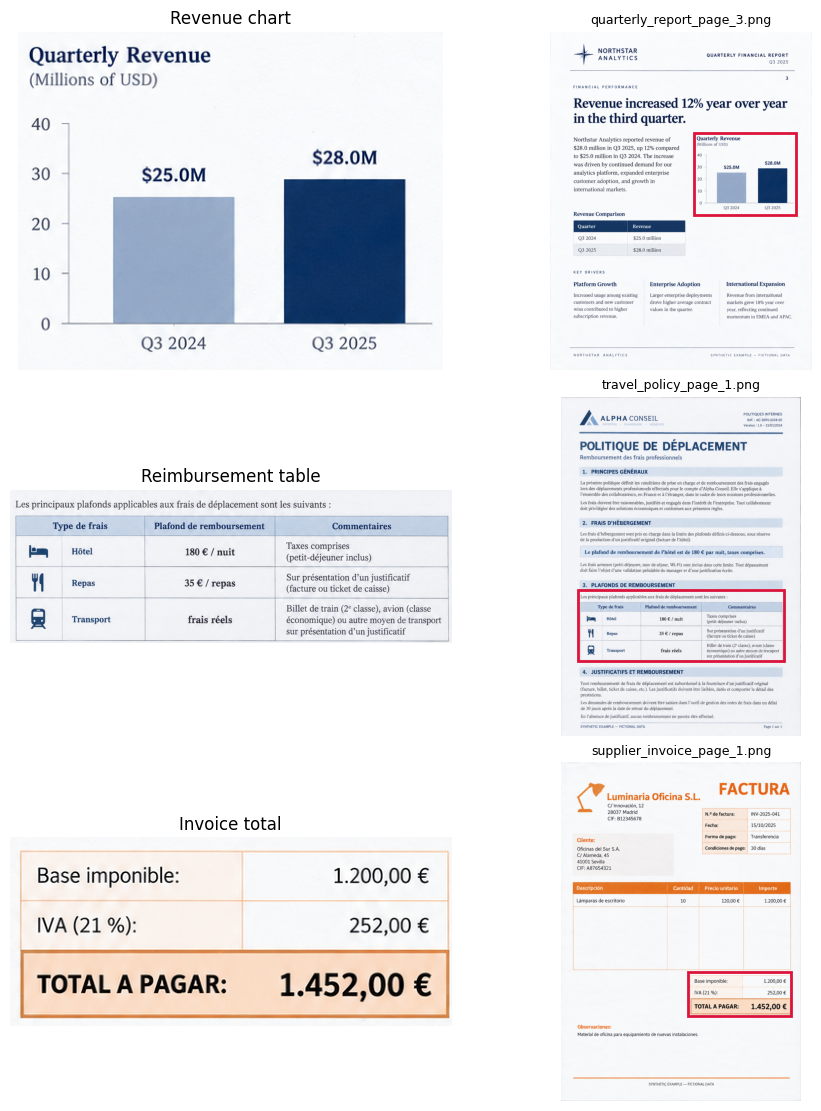

In [30]:
# Each entry stores a display label, a source filename, and a relative box
# in (left, top, right, bottom) order.
regions = [
    ("Revenue chart", "quarterly_report_page_3.png", (0.55, 0.30, 0.94, 0.54)),
    ("Revenue comparison table", "quarterly_report_page_3.png", (0.08, 0.52, 0.53, 0.67)),
    ("Key revenue drivers", "quarterly_report_page_3.png", (0.08, 0.70, 0.94, 0.88)),
    ("Reimbursement table", "travel_policy_page_1.png", (0.07, 0.57, 0.93, 0.78)),
    ("Hotel reimbursement paragraph", "travel_policy_page_1.png", (0.07, 0.35, 0.93, 0.53)),
    ("Invoice line items", "supplier_invoice_page_1.png", (0.05, 0.35, 0.96, 0.62)),
    ("Invoice total", "supplier_invoice_page_1.png", (0.53, 0.62, 0.96, 0.75)),
    ("Laptop specifications table", "product_spec_page_1.png", (0.05, 0.30, 0.56, 0.74)),
]
# Convert the boxes to pixels for cropping and keep them for drawing on the source pages.
# Index each crop as a separate document using only its image.
region_boxes = [pixel_box(pages[name], box) for _, name, box in regions]
region_crops = [pages[name].crop(box) for (_, name, _), box in zip(regions, region_boxes)]
region_multi, _, _ = encode(region_crops, "document")

# The expected labels are used by show_ranking to mark the intended matches.
region_queries = {
    "Bar chart comparing third-quarter revenue in 2024 and 2025": "Revenue chart",
    "Table comparing hotel, meals and transport reimbursement limits": "Reimbursement table",
    "Where are the subtotal, VAT, and grand total on the invoice?": "Invoice total",
}
region_query_multi, _, _ = encode(list(region_queries), "query")
# MaxSim produces one score per query–crop pair using their token vectors.
region_scores = maxsim(region_query_multi, region_multi)
region_labels = [label for label, _, _ in regions]
show_ranking("Text-to-region search (MaxSim)", list(region_queries), region_scores,
             region_labels, list(region_queries.values()), top=2)

# Use the winning crop's index to look up the source page and draw its original box.
fig, axes = plt.subplots(len(region_queries), 2, figsize=(9, 11), layout="constrained")
for scores, (crop_ax, page_ax) in zip(region_scores, axes):
    winner = scores.argmax().item()
    label, name, _ = regions[winner]
    left, top, right, bottom = region_boxes[winner]
    crop_ax.imshow(region_crops[winner])
    crop_ax.set_title(label)
    page_ax.imshow(pages[name])
    page_ax.add_patch(Rectangle((left, top), right - left, bottom - top,
                                fill=False, edgecolor="crimson", linewidth=2))
    page_ax.set_title(name, fontsize=9)
    for ax in (crop_ax, page_ax):
        ax.axis("off")
plt.show()

## 11. Discover document groups in an unlabeled archive

Here we generate nine synthetic pages from three organizations. Each organization uses its own accent color and contributes an invoice, a quarterly report, and a travel policy. All nine pages share a layout, so a cluster that groups by document family has to look past the template.

Cluster the normalized single vectors with Ward linkage and inspect the page closest to each cluster’s mean. We use three clusters because this toy archive contains three families. The family labels appear only in the output so you can check what the model grouped together.

In [31]:
from matplotlib import font_manager
from PIL import ImageDraw, ImageFont

# Render searchable examples from data so the notebook is self-contained.
regular = font_manager.findfont("DejaVu Sans")
bold = font_manager.findfont(font_manager.FontProperties(family="DejaVu Sans", weight="bold"))
body_font = ImageFont.truetype(regular, 21)
heading_font = ImageFont.truetype(bold, 24)
title_font = ImageFont.truetype(bold, 36)
org_font = ImageFont.truetype(bold, 18)

# Give each organization an accent color that it uses across all document types.
organizations = [
    ("Cedar Works", "#174868"),
    ("Harbor Studio", "#7b4533"),
    ("Summit Labs", "#205b48"),
]


# Use the same page layout for reports, policies, and invoices.
def render_archive_page(org, color, title, record, caption, columns, rows, summary):
    page = Image.new("RGB", (760, 960), "#fbfaf7")
    draw = ImageDraw.Draw(page)
    ink = "#152736"
    draw.rectangle((0, 0, 760, 14), fill=color)
    draw.text((48, 49), org.upper(), font=org_font, fill=color)
    draw.text((48, 100), title, font=title_font, fill=ink)
    draw.text((48, 165), record, font=heading_font, fill=color)
    draw.text((48, 210), caption, font=body_font, fill=ink)

    # Reuse the column positions for the table header and each row.
    x_positions = (64, 389, 545)
    draw.rectangle((48, 275, 712, 326), fill=color)
    for x, column in zip(x_positions, columns):
        draw.text((x, 288), column, font=org_font, fill="white")
    for row_number, row in enumerate(rows):
        y = 326 + 62 * row_number
        draw.rectangle((48, y, 712, y + 61), fill="#edf1f1" if row_number % 2 == 0 else "white")
        for x, value in zip(x_positions, row):
            draw.text((x, y + 16), value, font=body_font, fill=ink)
    draw.line((48, 550, 712, 550), fill=color, width=2)
    draw.text((48, 571), summary, font=heading_font, fill=color)
    draw.text((48, 892), "SYNTHETIC SAMPLE", font=org_font, fill=color)
    return page


# Reuse this template for the near-duplicate test so only the invoice fields differ.
def render_invoice(org, color, number, service, quantity, unit_price):
    subtotal = quantity * unit_price
    return render_archive_page(
        org, color, "Supplier invoice", f"Invoice {number}", "Bill to: Clear Field Services  |  Net 30 days",
        ("Description", "Quantity", "Amount"),
        [(service, str(quantity), f"${subtotal:,.2f}"), ("Sales tax", "10%", f"${subtotal / 10:,.2f}")],
        f"TOTAL DUE: ${subtotal * 1.10:,.2f}",
    )


# Create one page of each type per organization. Keep the type labels for checking the clusters.
synthetic_archive = []
for i, (org, color) in enumerate(organizations):
    invoice = render_invoice(org, color, f"INV-{1042 + 10 * i}",
                             ["Desk lamps", "Monitor stands", "Storage trays"][i], 6 + i, 80 + 5 * i)
    report = render_archive_page(
        org, color, "Quarterly performance report", f"Q{2 + i} 2025", "Operating results and year-over-year growth",
        ("Metric", "Prior year", "This year"),
        [("Revenue", f"${22 + i}M", f"${26 + i}M"), ("Gross margin", "58%", "61%"),
         ("New customers", str(97 + i), str(116 + 2 * i))],
        "Revenue and gross margin increased",
    )
    policy = render_archive_page(
        org, color, "Travel reimbursement policy", f"Revision {i + 1}", "Rules for employee business travel",
        ("Expense", "Limit", "Basis"),
        [("Hotel", f"${180 + 10 * i}", "Per night"), ("Meals", f"${45 + 5 * i}", "Per day"),
         ("Rail travel", "Actual cost", "With receipt")],
        "Submit receipts within 30 days",
    )
    synthetic_archive.extend([(org, "Invoice", invoice), (org, "Report", report), (org, "Policy", policy)])

Cluster 1: Cedar Works (Report), Harbor Studio (Report), Summit Labs (Report)
Cluster 2: Cedar Works (Policy), Harbor Studio (Policy), Summit Labs (Policy)
Cluster 3: Cedar Works (Invoice), Harbor Studio (Invoice), Summit Labs (Invoice)


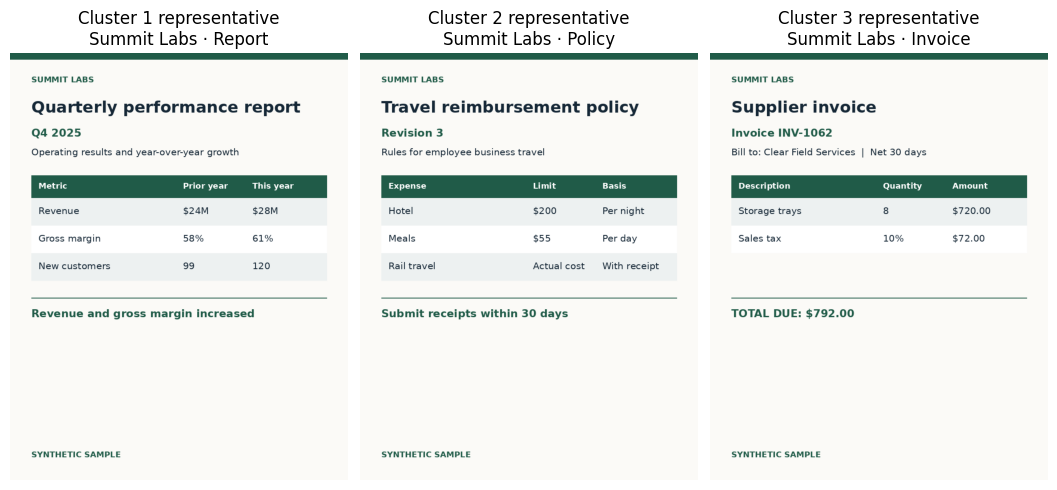

In [32]:
# Pass only page images to the encoder and keep one vector per page.
synthetic_pages = [page for _, _, page in synthetic_archive]
_, synthetic_vectors, _ = encode(synthetic_pages, "document")
# Normalize each vector so Euclidean distance between pages tracks cosine similarity.
archive_vectors = torch.nn.functional.normalize(synthetic_vectors, dim=-1)
# Ward linkage merges groups to minimize the increase in within-group variance.
# Cut the hierarchy at three clusters for this three-family example.
cluster_ids = fcluster(linkage(archive_vectors.numpy(), method="ward"), t=3, criterion="maxclust")
clusters = sorted(set(cluster_ids))

fig, axes = plt.subplots(1, len(clusters), figsize=(3.5 * len(clusters), 4.7),
                         squeeze=False, layout="constrained")
for cluster_id, ax in zip(clusters, axes[0]):
    members = np.flatnonzero(cluster_ids == cluster_id).tolist()
    vectors = archive_vectors[members]
    # For unit vectors, the largest dot product with the mean identifies the closest page.
    representative = members[(vectors @ vectors.mean(dim=0)).argmax().item()]
    org, family, page = synthetic_archive[representative]
    # Read the known family labels after clustering to see what ended up together.
    print(f"Cluster {cluster_id}: " + ", ".join(
        f"{synthetic_archive[i][0]} ({synthetic_archive[i][1]})" for i in members))
    ax.imshow(page)
    ax.set_title(f"Cluster {cluster_id} representative\n{org} · {family}")
    ax.axis("off")
plt.show()

## 12. Surface near-duplicate invoices

A second scan of an invoice should retrieve the original, but an invoice for one extra item can look almost the same. Search with a tilted, blurred JPEG of **INV-1042**. The archive contains the clean original and a second invoice from the same supplier for the same items. Its invoice number and total differ.

Compare the scores for both candidates. Similarity can shortlist records for review. An automatic merge would also need to check fields such as invoice number and total.

1. Original · INV-1042              cosine 0.9935
2. Separate invoice · INV-1043      cosine 0.9744
3. Summit Labs · Invoice            cosine 0.9033
Original rank: 1 of 10
Same-template invoice rank: 2 of 10


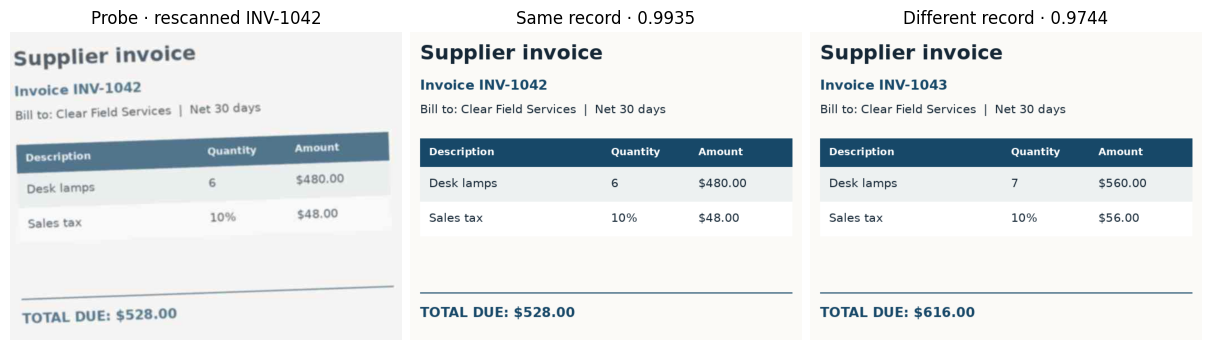

In [33]:
from io import BytesIO

from PIL import ImageEnhance, ImageFilter

original_invoice = synthetic_pages[0]
org, color = organizations[0]
# The second invoice shares a supplier and layout but changes the ID and quantity.
other_invoice = render_invoice(org, color, "INV-1043", "Desk lamps", 7, 80)

# Simulate an alternate scan of INV-1042 without changing its contents.
rescan = original_invoice.rotate(2, resample=Image.Resampling.BICUBIC, fillcolor="#e0e4e5")
rescan = ImageEnhance.Contrast(rescan).enhance(0.72).filter(ImageFilter.GaussianBlur(1.1))
# Compress and decode the simulated scan in memory so it includes JPEG artifacts.
jpeg = BytesIO()
rescan.save(jpeg, format="JPEG", quality=32)
jpeg.seek(0)
with Image.open(jpeg) as decoded:
    rescan = decoded.convert("RGB")

# Reuse the archive vectors and encode only the probe and the second invoice.
_, extra_vectors, _ = encode([rescan, other_invoice], "document")
rescan_vector, other_vector = torch.nn.functional.normalize(extra_vectors, dim=-1)
candidate_vectors = torch.cat([archive_vectors, other_vector.unsqueeze(0)])
candidate_labels = ["Original · INV-1042"] + [
    f"{org} · {family}" for org, family, _ in synthetic_archive[1:]
] + ["Separate invoice · INV-1043"]
# The dot product of two normalized vectors is their cosine similarity.
duplicate_scores = candidate_vectors @ rescan_vector
duplicate_ranking = duplicate_scores.argsort(descending=True).tolist()

# Show the nearest candidates and report where both known invoices landed.
for rank, i in enumerate(duplicate_ranking[:3], start=1):
    print(f"{rank}. {candidate_labels[i]:<32} cosine {duplicate_scores[i]:.4f}")
print(f"Original rank: {duplicate_ranking.index(0) + 1} of {len(candidate_labels)}")
print(f"Same-template invoice rank: {duplicate_ranking.index(len(candidate_labels) - 1) + 1} of {len(candidate_labels)}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), layout="constrained")
for ax, page, title in zip(axes, [rescan, original_invoice, other_invoice], [
    "Probe · rescanned INV-1042",
    f"Same record · {duplicate_scores[0]:.4f}",
    f"Different record · {duplicate_scores[-1]:.4f}",
]):
    # Crop the display only, keeping the invoice number and total in view.
    ax.imshow(page.crop((30, 85, 730, 635)))
    ax.set_title(title)
    ax.axis("off")
plt.show()

## Optional: measure encoding speed on your machine

This cell measures page images encoded per second using images already decoded in memory. Throughput varies with hardware, precision, and batch size.

In [34]:
# Repeat the already decoded images to create a 32-page workload.
batch = (list(pages.values()) * 6)[:32]
with torch.inference_mode():
    model.encode_document(batch[:4], batch_size=4)  # warm-up
    # CUDA runs asynchronously. Drain queued work before starting and after encoding.
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    model.encode_document(batch, batch_size=16)
    if device == "cuda":
        torch.cuda.synchronize()
elapsed = time.perf_counter() - start
gpu = torch.cuda.get_device_name() if device == "cuda" else "CPU"
print(f"{len(batch) / elapsed:.1f} page images per second on {gpu} ({dtype}), "
      f"{len(batch)} pages already decoded in memory")

43.7 page images per second on NVIDIA GeForce RTX 4090 (torch.bfloat16), 32 pages already decoded in memory


## Resources

The [model card](https://huggingface.co/ibm-granite/granite-embedding-748m-vision-r2) has the benchmarks and training details. The model repository also includes `retrieval_example.py` for command-line retrieval and `maxsim_heatmap.py` for interactive HTML heatmaps.